# Gene set analysis and GRN inference on PBMCs

*Python port of the R vignette [Gene set analysis and GRN inference on PBMCs](https://gregorlueg.github.io/bixverse/articles/bag_of_genes_single_cells.html). Original author: Gregor Lueg.*

## Intro

This vignette demonstrates the gene set scoring, spatial autocorrelation and
gene regulatory network (GRN) inference methods available in `bixverse`. It
picks up where the [PBMC vignette](pbmc_single_cell.ipynb) left off: QC,
normalisation, PCA, nearest neighbours, clustering and UMAP are all assumed
to be done already. If you have not read the
[design choices](design_single_cell.ipynb) and the
[introductory vignette](thinking_single_cell.ipynb), please do so first.

The methods fall into three broad categories:

- The first, module scores, AUCell and VISION, takes *pre-defined* gene sets
  and scores them per cell. ULM and MLM do the same for signed networks and
  show up after SCENIC, scoring its TF-to-gene links.
- The second, Hotspot and SCENIC, *discovers* gene programmes and regulatory
  relationships from the data itself.
- The third, NMF, also *discovers* gene programmes, via matrix factorisation,
  which is a different angle from SCENIC and Hotspot.

The LDA topic models over the binarised regulons are not ported to Python
yet, so that part of the story is missing here.

We use the PBMC3k dataset throughout. At 2,700 cells this is likely too small
for the GRN methods to produce biologically meaningful results, but it is
large enough to show the API and the workflow end to end. On real datasets
with tens of thousands of cells the same code applies unchanged.

In [1]:
import tempfile
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import (
    AucellParams,
    LmActivityParams,
    NeighboursParams,
    NmfConsensusParams,
    ScenicParams,
    VisionParams,
)

### Rebuilding the processed object

We reconstruct the processed `SingleCells` object from the PBMC vignette: it
downloads the data, runs QC, HVG selection, PCA, neighbour computation,
Leiden clustering and UMAP.

In [2]:
pbmc3k_path = bv.io.download_pbmc3k()

tempdir_pbmc = tempfile.TemporaryDirectory()

sc = bv.io.load_mtx(
    Path(tempdir_pbmc.name) / "pbmc3k",
    bv.io.get_cell_ranger_params(pbmc3k_path),
)

sc.rename_var_col("column1", "gene_symbol")

var = sc.var()
ensembl_to_symbol = dict(zip(var["gene_id"], var["gene_symbol"], strict=True))
symbol_to_ensembl = dict(zip(var["gene_symbol"], var["gene_id"], strict=True))

# gene set proportions for QC
gs_of_interest = {
    "MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list(),
    "Ribo": var.filter(pl.col("gene_symbol").str.contains("^RP[SL]"))[
        "gene_id"
    ].to_list(),
}
bv.qc.gene_set_proportions(sc, gs_of_interest, streaming=False)

# MAD QC
qc_df = sc.obs(cols=["cell_id", "lib_size", "nnz", "MT"])
qc = bv.qc.run_cell_qc(
    {
        "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
        "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
        "MT": qc_df["MT"].to_numpy(),
    },
    sc.cells_to_keep,
    directions={"log10_lib_size": "twosided", "log10_nnz": "twosided", "MT": "above"},
    threshold=3.0,
)
sc.add_obs(pl.DataFrame({"cell_idx": qc.cell_idx, "outlier": qc.combined}))
sc.set_cells_to_keep(qc.cell_idx[~qc.combined])

# HVG, PCA, neighbours, clustering, UMAP
bv.pp.find_hvg(sc, hvg_no=2000)
bv.pp.calculate_pca(sc, no_pcs=30, sparse_svd=True)
bv.graph.find_neighbours(
    sc, neighbours_params=NeighboursParams(knn_method="exhaustive")
)
bv.graph.find_clusters(sc, res=1.5, name="leiden_clusters")
bv.embed.umap(sc)

# UMAP coordinates for reuse
umap_df = bv.pl.extract_embedding_data(sc, "umap").rename(
    {"dim_1": "umap_1", "dim_2": "umap_2"}
)

sc

SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpvjctqbx5/pbmc3k',
  cells=2700 (kept 2490), genes=11139,
  hvg=True, pca=True, embeddings=['umap'],
  knn=True, graph=True, magic=False, residuals=False,
  stale=none
)

The scores below come back as a cells x gene sets matrix. To look at several
of them on the UMAP at once, a small facet helper:

In [3]:
def plot_scores_on_umap(scores, label, scale=False, ncol=2):
    """Facet the columns of an `ScMatrixRes` on the UMAP."""
    df = scores.frame().join(umap_df, on="cell_id")
    n = len(scores.columns)
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.5 * ncol, 4 * nrow), squeeze=False)
    for ax, col in zip(axes.flat, scores.columns, strict=False):
        v = df[col].to_numpy()
        if scale:
            v = (v - v.min()) / (v.max() - v.min())
        pts = ax.scatter(df["umap_1"], df["umap_2"], c=v, s=1, cmap="viridis")
        ax.set_title(col)
        ax.set_xticks([])
        ax.set_yticks([])
        fig.colorbar(pts, ax=ax, label=label)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    fig.tight_layout()

## Gene set scoring

### Module scores

The simplest approach to gene set activity is the module score from
[Tirosh et al. (2016)](https://www.science.org/doi/10.1126/science.aad0501):
for each cell, compute the mean expression of the gene set and subtract the
mean expression of a size-matched control set drawn from the same expression
bins. We will just use some lineage-specific genes to have pretty
visualisations.

In [4]:
lineage_symbols = {
    "T cell": [
        "CD3D", "CD3E", "CD3G", "CD2", "IL7R", "CD7", "LEF1", "TCF7", "LTB", "TRAC",
    ],
    "Cytotoxic NK": [
        "NKG7", "GNLY", "GZMA", "GZMB", "GZMH", "PRF1", "CST7", "KLRD1", "KLRB1",
        "FGFBP2",
    ],
    "B cell": [
        "CD79A", "CD79B", "MS4A1", "BANK1", "IGHM", "IGHD", "CD74", "HLA-DQA1",
        "TCL1A", "VPREB3",
    ],
    "Monocyte": [
        "CD14", "LYZ", "S100A8", "S100A9", "S100A12", "CST3", "FCN1", "VCAN",
        "MNDA", "TYROBP",
    ],
}  # fmt: skip

# drop the symbols not in the data
lineage_sets = {
    name: [symbol_to_ensembl[s] for s in genes if s in symbol_to_ensembl]
    for name, genes in lineage_symbols.items()
}

module_scores = bv.pathways.module_scores(sc, lineage_sets)

module_scores

ScMatrixRes: 2490 cells x 4 gene sets (T cell, Cytotoxic NK, B cell, Monocyte)

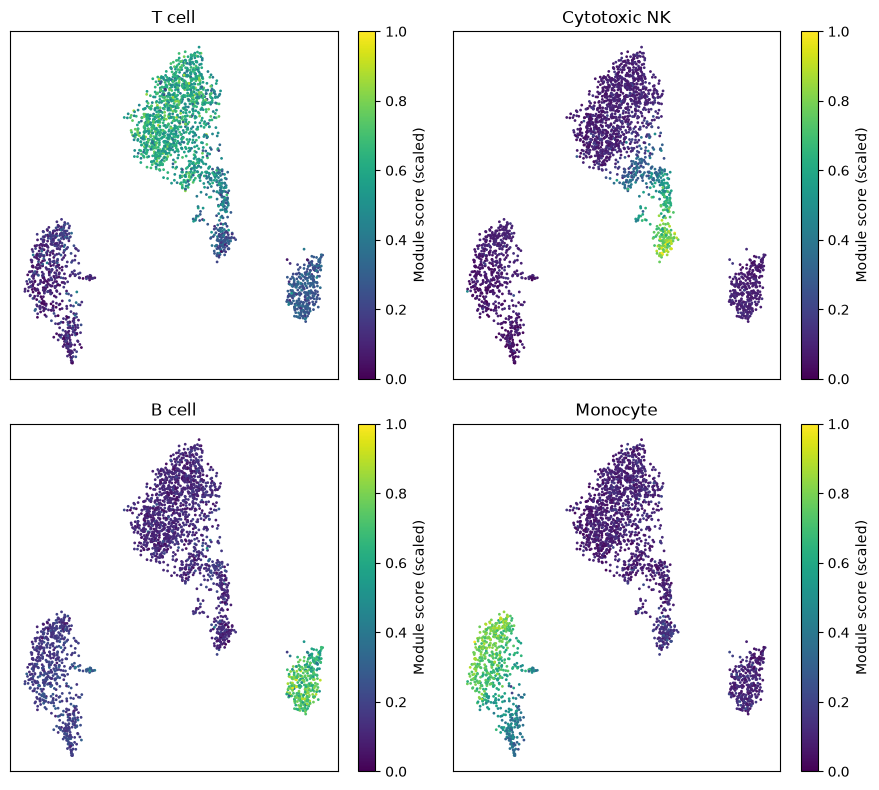

In [5]:
# scale the scores to make them more comparable across sets
plot_scores_on_umap(module_scores, "Module score (scaled)", scale=True)
plt.show()

Let's imagine you want to add the scores to the internal DB. There are
helpers for this, too: `get_data()` turns the scores into an obs frame keyed
on `cell_idx`, which `add_obs()` takes as is.

In [6]:
sc.add_obs(bv.pathways.get_data(module_scores))

sc.obs(filtered=True).head()

cell_idx,cell_id,nnz,lib_size,to_keep,MT,Ribo,outlier,leiden_clusters,T cell,Cytotoxic NK,B cell,Monocyte
u32,str,f64,f64,bool,f64,f64,bool,i32,f64,f64,f64,f64
0,"""AAACATACAACCAC-1""",778.0,2418.0,true,0.03019,0.437138,false,0,0.420079,-0.21635,-0.255572,-0.716901
1,"""AAACATTGAGCTAC-1""",1346.0,4896.0,true,0.03799,0.424632,false,2,-0.602224,-0.417916,1.355304,-0.648365
2,"""AAACATTGATCAGC-1""",1126.0,3144.0,true,0.008906,0.317112,false,0,0.362761,-0.332543,-0.333236,-0.632468
3,"""AAACCGTGCTTCCG-1""",953.0,2632.0,true,0.017477,0.243161,false,3,-1.022965,-0.217898,0.130342,1.300652
4,"""AAACCGTGTATGCG-1""",520.0,979.0,true,0.012257,0.149132,false,6,-0.549039,1.858813,-0.123326,-0.429685


As we can appreciate, this has now added the new columns.

### AUCell

[AUCell](https://www.nature.com/articles/nmeth.4463) ranks genes within each
cell by expression and summarises where the gene set lands in that ranking.
More robust to outliers than a simple mean. `bixverse` gives you three
statistics via `AucellParams`, all reading the same ranking but weighting it
differently:

- `"recovery"`, the default, is the recovery-curve AUC under a rank cutoff,
  i.e. what Aibar et al. published. Top-heavy: only genes inside the top
  `max_rank` contribute, so it is the sharper instrument for marker sets and
  the one to use for SCENIC.
- `"wilcox"` is the AUC from the Mann-Whitney U statistic over the full
  ranking. Its null sits at 0.5 whatever the gene set size, which makes it a
  safe pick for pathway activity, but the flatter score does not split into
  on/off populations.
- `"ap"` is average precision. Most top-heavy of the three, but its null
  tracks gene set prevalence, so don't compare raw values across sets of
  different size unless you switch `standardise` on.

We use the `"wilcox"` here.

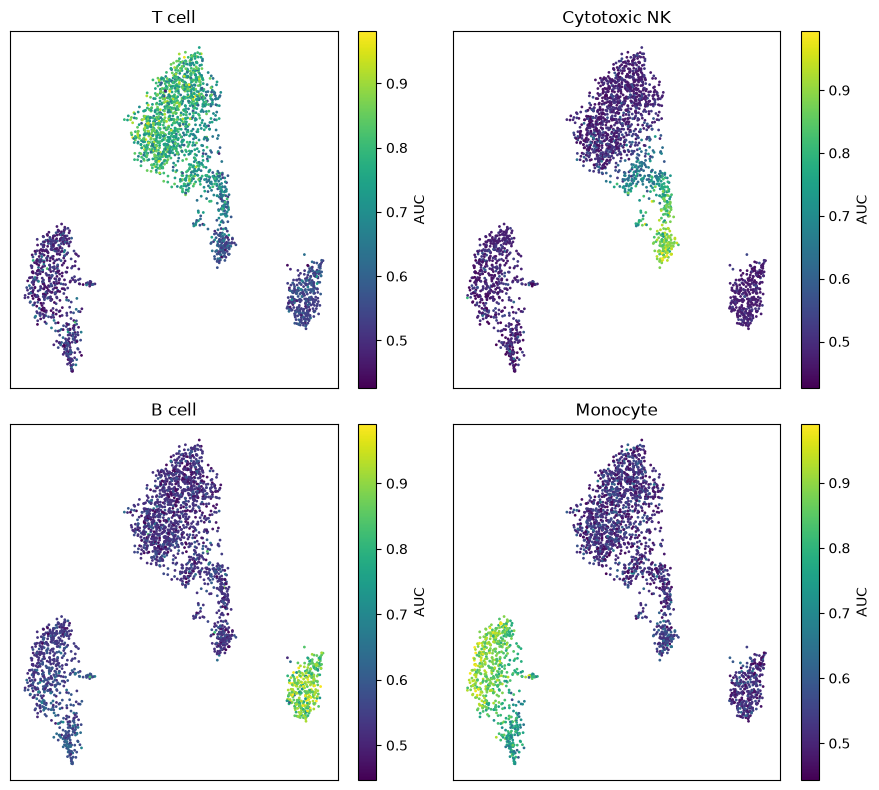

In [7]:
auc_scores = bv.pathways.aucell(
    sc, lineage_sets, aucell_params=AucellParams(auc_type="wilcox")
)

plot_scores_on_umap(auc_scores, "AUC")
plt.show()

### VISION with spatial autocorrelation

Scoring gene sets is useful, but a natural follow-up question is: *are these
scores spatially structured on the cell neighbourhood graph, or just noise?*
[VISION](https://www.nature.com/articles/s41467-019-12235-0) provides a
permutation-based test of spatial autocorrelation (Geary's C) on the kNN
graph. Gene sets with significant autocorrelation are those whose activity
varies smoothly across cell neighbourhoods, a strong indication that the
signal is biologically meaningful rather than random.

VISION expects gene sets in a signed format with `pos` and (optionally) `neg`
components. In the case of our cell lineage genes, we could use the other
cell type's markers as negatives, but we will just leave it blank here.

In [8]:
vision_gs = {name: {"pos": genes} for name, genes in lineage_sets.items()}

vision_res = bv.pathways.vision_w_autocor(
    sc, vision_gs, "pca", vision_params=VisionParams(n_perm=500)
)

vision_res.auto_cor

gene_set_name,auto_cor,p_val,fdr
str,f64,f64,f64
"""T cell""",0.772272,0.001996,0.002661
"""Cytotoxic NK""",0.460837,0.015968,0.015968
"""B cell""",0.608082,0.001996,0.002661
"""Monocyte""",0.607321,0.001996,0.002661


Unsurprisingly, all of these gene sets show highly significant spatial
correlation.

## Hotspot

Where the methods above test *pre-defined* gene sets, Hotspot
([DeTomaso & Yosef, 2021](https://www.cell.com/cell-systems/fulltext/S2405-4712(21)00114-9))
discovers gene programmes *de novo* by testing each gene for spatial
autocorrelation on the kNN graph and then grouping the significant genes by
their local correlation structure.

### Gene autocorrelation

The first step computes Geary's C for every gene against the neighbour
graph. Genes with significant autocorrelation are those whose expression
varies smoothly across neighbouring cells, i.e., genes that mark spatially
coherent programmes.

In [9]:
hotspot_autocor = bv.pathways.hotspot_autocor(sc).with_columns(
    gene_symbol=pl.col("gene_id").replace_strict(ensembl_to_symbol)
)

hotspot_autocor.sort("fdr").head(25)

gene_id,gearys_c,z_score,pval,fdr,gene_symbol
str,f64,f64,f64,f64,str
"""ENSG00000162444""",0.282709,43.65414,0.0,0.0,"""RBP7"""
"""ENSG00000142676""",0.225809,45.495686,0.0,0.0,"""RPL11"""
"""ENSG00000126709""",0.27859,41.387817,0.0,0.0,"""IFI6"""
"""ENSG00000119535""",0.305395,54.686909,0.0,0.0,"""CSF3R"""
"""ENSG00000234184""",0.290092,46.086132,0.0,0.0,"""RP5-887A10.1"""
…,…,…,…,…,…
"""ENSG00000116667""",0.198329,42.559952,0.0,0.0,"""C1orf21"""
"""ENSG00000143947""",0.36961,66.629669,0.0,0.0,"""RPS27A"""
"""ENSG00000115523""",0.601407,155.955017,0.0,0.0,"""GNLY"""


You should get a set of well known cell type markers here...

### Gene-gene local correlations and modules

Taking the significant genes forward, we compute pairwise local correlations
and cluster them into modules. Each module represents a group of genes that
are not only individually autocorrelated but also co-vary locally, a much
stronger signal than global correlation alone.

In [10]:
sig_genes = hotspot_autocor.filter(pl.col("fdr") <= 0.05)["gene_id"].to_list()

hotspot_cor = bv.pathways.hotspot_gene_cor(sc, genes_to_take=sig_genes, verbose=True)

hotspot_cor

Using provided kNN graph.
Loading 2788 genes...
Loaded data in 3.86ms
Centering gene expression...
Centered in 4.27ms
Computing wy, eg2 and per-gene max values...
Computed wy/eg2/maxs in 11.31ms
Computing pairwise correlations (GEMM)...
Computed GEMM in 25.38ms
Done!


Hotspot gene-gene local correlation results
  Genes: 2788
  Cells: 2490
  Modules: not yet computed (see generate_hotspot_membership)

This returns a `Hotspot` result. Let's add the membership.

Not ported to Python yet: the module heatmap (`plot()` on a `Hotspot`).

In [11]:
hotspot_cor = bv.pathways.generate_hotspot_membership(hotspot_cor)

hotspot_cor

Hotspot gene-gene local correlation results
  Genes: 2788
  Cells: 2490
  Modules: 53 (1437 genes assigned, 1351 unassigned)

Let's pull out the genes:

In [12]:
membership = (
    bv.pathways.get_hotspot_membership(hotspot_cor)
    .with_columns(gene_symbol=pl.col("gene_id").replace_strict(ensembl_to_symbol))
    .drop_nulls("cluster_member")
)

membership.sort("cluster_member").head(20)

gene_id,cluster_member,gene_symbol
str,i64,str
"""ENSG00000197530""",0,"""MIB2"""
"""ENSG00000189409""",0,"""MMP23B"""
"""ENSG00000116663""",0,"""FBXO6"""
"""ENSG00000160050""",0,"""CCDC28B"""
"""ENSG00000143119""",0,"""CD53"""
…,…,…
"""ENSG00000116667""",0,"""C1orf21"""
"""ENSG00000134308""",0,"""YWHAQ"""
"""ENSG00000115956""",0,"""PLEK"""


The resulting modules should roughly correspond to the major cell-type
programmes in PBMCs (T cell, monocyte, B cell, NK cell signatures, etc.).
Let's score the six largest modules with VISION and put them on the UMAP.

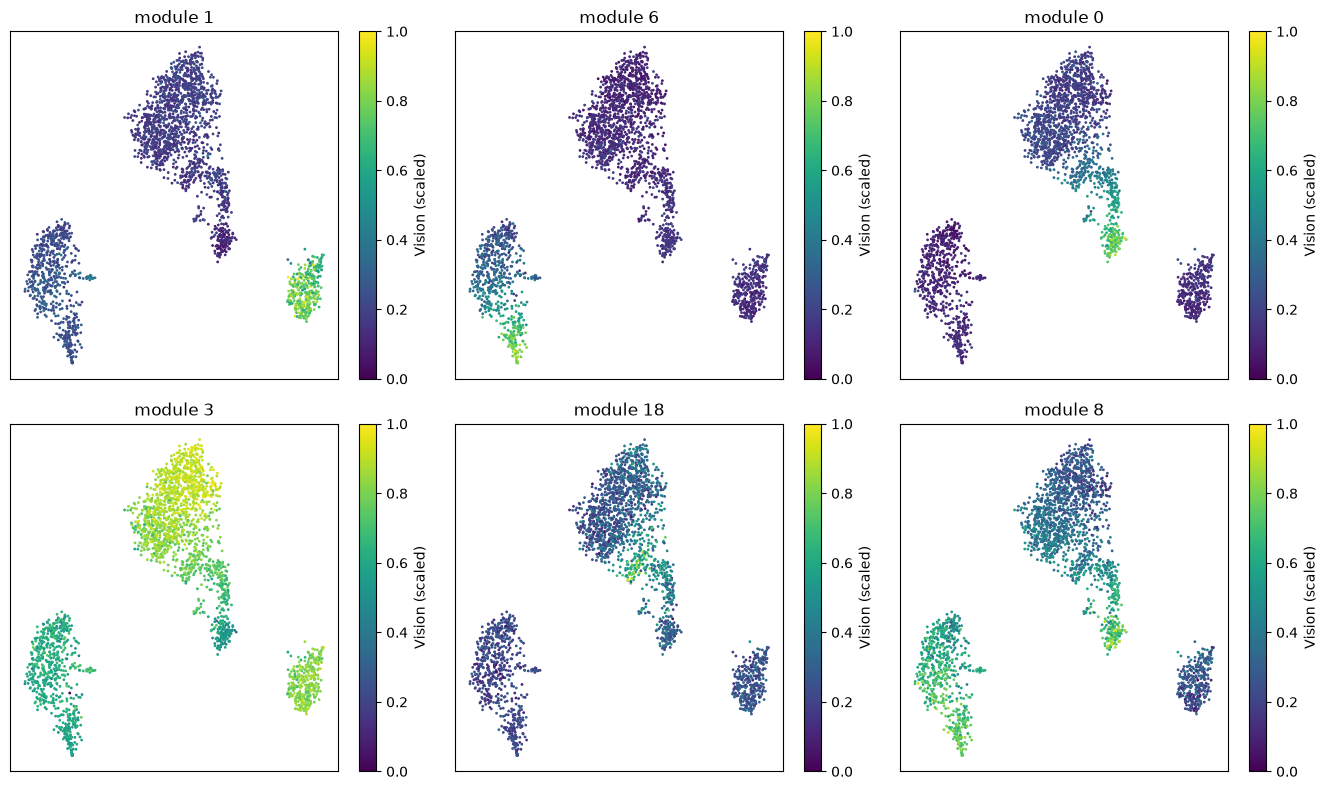

In [13]:
hotspot_top_k = 6

# largest by gene count, ties broken by id
top_modules = (
    membership.group_by("cluster_member")
    .len()
    .sort(["len", "cluster_member"], descending=[True, False])
    .head(hotspot_top_k)["cluster_member"]
    .to_list()
)

hotspot_gene_sets = {
    f"module {m}": {
        "pos": membership.filter(pl.col("cluster_member") == m)["gene_id"].to_list()
    }
    for m in top_modules
}

vision_scores_hotspot = bv.pathways.vision(sc, hotspot_gene_sets)

# min max individually for prettier visualisations
plot_scores_on_umap(vision_scores_hotspot, "Vision (scaled)", scale=True, ncol=3)
plt.show()

## SCENIC

[SCENIC](https://www.nature.com/articles/nmeth.4463) infers gene regulatory
networks by asking: for each gene, which transcription factors (TFs) best
predict its expression? The original implementation uses either random
forests or GRNBoost2 (gradient boosted trees) to regress each target gene on
all TFs, then extracts feature importances as a proxy for regulatory
strength.

The `bixverse` implementation re-implements this in Rust with several
optimisations that make the RF and ExtraTrees paths substantially faster
than the single-target-at-a-time approach used by GRNBoost2:

- **Quantisation**: TF expression values are discretised into 256 bins (u8),
  so histogram construction during tree building operates on single bytes
  and fits comfortably in L1 cache.
- **Multi-output batching**: up to 64 target genes share a single tree
  structure. The histogram construction cost is paid once per node per
  feature, but the split score aggregates variance reduction across all
  targets in the batch. This amortises the dominant cost of tree building
  across targets.
- **Correlated gene batching**: rather than assigning genes to batches
  randomly, an optional SVD + k-means step groups co-expressed genes
  together so that the shared tree structure is more informative for each
  target in the batch.
- **GRNBoost2 with histogram subtraction**: for the gradient boosted path
  (single-target), the code builds full-feature histograms at each node and
  derives the larger child via parent-minus-smaller subtraction, avoiding a
  redundant scan of the larger child's samples. OOB early stopping prevents
  overfitting and is the main source of speedup.

On the 2,700-cell PBMC3k dataset these optimisations are not that
noticeable... The data is too small for any method to take long. On datasets
with tens of thousands of cells and thousands of TFs, the RF/ET multi-output
path comfortably outperforms GRNBoost2. You need to just decide if you are
okay with the batching of genes. The big signals get recovered again and
again (from empirical testing).

### Gene filtering

SCENIC first filters genes by minimum total counts and minimum proportion of
expressing cells to remove uninformative targets.

In [14]:
scenic_genes = bv.pathways.scenic_gene_filter(
    sc, scenic_params=ScenicParams(min_counts=50)
)

len(scenic_genes)

5494

### Transcription factor list

We need a list of known TFs. The Aerts lab provides a curated list for human
(`allTFs_hg38.txt` from their
[cisTarget resources](https://resources.aertslab.org/cistarget/tf_lists/)).
The Python package does not ship a copy yet, so we fetch it from there and
map it to Ensembl IDs.

In [15]:
tf_url = "https://resources.aertslab.org/cistarget/tf_lists/allTFs_hg38.txt"
with urllib.request.urlopen(tf_url) as f:
    tf_symbols = f.read().decode().split()

tf_ids = [symbol_to_ensembl[tf] for tf in tf_symbols if tf in symbol_to_ensembl]

len(tf_ids)

1100

### GRN inference

With genes and TFs in hand, we run the GRN inference step. Here we use
random forests with a batch size of 64 to illustrate the multi-output path.

In [16]:
scenic_res = bv.pathways.scenic_grn(
    sc,
    tf_ids,
    genes_to_take=scenic_genes,
    scenic_params=ScenicParams(learner_type="randomforest", gene_batch_size=64),
    verbose=True,
)

scenic_res

Loaded, filtered and quantised TF data (n: 482) in: 1.63ms
Computing gene loadings: 5494 genes, 2490 subsampled cells, 50 components
PCA (streaming): Scaling batch 1/6 (1024 genes each)
PCA (streaming): Scaling batch 2/6 (1024 genes each)
PCA (streaming): Scaling batch 3/6 (1024 genes each)
PCA (streaming): Scaling batch 4/6 (1024 genes each)
PCA (streaming): Scaling batch 5/6 (1024 genes each)
PCA (streaming): Scaling batch 6/6 (1024 genes each)
PCA (streaming): finished scaling in 13.79ms
PCA (streaming): finished calculations in 135.28ms
PCA (streaming): total run time -> 162.51ms
Clustering 5494 genes into 86 groups


Read and filtered 5494 target genes in 8.82ms
Running SCENIC (RandomForest) on 5494 genes (482 TFs, 2490 cells, 141 batches of up to 64)


  Progress: 10% (15 / 141 batches, 1.95s)


  Progress: 20% (29 / 141 batches, 3.17s)


  Progress: 30% (43 / 141 batches, 4.54s)


  Progress: 40% (57 / 141 batches, 6.08s)


... (3 outputs left out)

  Progress: 80% (113 / 141 batches, 12.29s)


  Progress: 90% (127 / 141 batches, 13.42s)


  Progress: 100% (141 / 141 batches, 14.76s)
SCENIC (RandomForest) GRN inference complete in 14.97s


ScenicGrn (GRN results)
  No genes:                 5494
  No TFs:                   482
  Applied learner:          randomforest
  TF to gene generated:     False
  CisTarget res generated:  False

If you are bored, you can run both methods (`learner_type="grnboost2"`) and
compare the importance scores. You will see very high correlations here (and
can explore the speed differences...)

### TF-to-gene refinement

The raw importance matrix is large and noisy. The next steps winnow it down
to a candidate regulatory network by keeping only the top TF-gene pairs and
filtering by pairwise expression correlation. Per gene only the TFs with an
`importance score >= mean(importance_score) + n_sd * sd(importance_score)`
for that gene are kept. Note that `n_sd` should be adjusted depending on the
learner: RF and ExtraTrees spread importance more evenly across TFs than
GRNBoost2, so a lower threshold (e.g. `n_sd=1`) is appropriate, whereas
GRNBoost2 concentrates importance onto fewer TFs and tolerates `n_sd=1.5` or
even `n_sd=2`.

In [17]:
scenic_res = bv.pathways.identify_tf_to_genes(scenic_res, n_sd=2.0, verbose=True)

scenic_res = bv.pathways.tf_to_genes_correlations(scenic_res, sc, verbose=True)

tf_gene_df = bv.pathways.get_tf_to_gene(scenic_res).with_columns(
    tf_symbol=pl.col("tf").replace_strict(ensembl_to_symbol),
    gene_symbol=pl.col("gene").replace_strict(ensembl_to_symbol),
)

tf_gene_df.sort("importance", descending=True).head(5)

Calculating pairwise correlations between the genes of interest.
Calculated pairwise correlations in 21.11ms


tf,gene,importance,pairwise_cor,cor_sign,tf_symbol,gene_symbol
str,str,f64,f64,i32,str,str
"""ENSG00000170345""","""ENSG00000120129""",0.274053,0.341508,1,"""FOS""","""DUSP1"""
"""ENSG00000066336""","""ENSG00000114013""",0.25875,0.344219,1,"""SPI1""","""CD86"""
"""ENSG00000139187""","""ENSG00000113088""",0.253827,0.258217,1,"""KLRG1""","""GZMK"""
"""ENSG00000170345""","""ENSG00000087074""",0.216636,0.192474,1,"""FOS""","""PPP1R15A"""
"""ENSG00000066336""","""ENSG00000165140""",0.213676,0.240562,1,"""SPI1""","""FBP1"""


### CisTarget motif enrichment

The final (and optional) step in the SCENIC pipeline validates the predicted
TF-gene links against known motif binding sites. This requires the CisTarget
motif ranking database and motif-to-TF annotation files from the
[Aerts lab resources](https://resources.aertslab.org/cistarget/), which
together are roughly 400 MB. The Python package has no downloader or reader
for them yet: `tf_to_genes_motif_enrichment()` takes the ranking as an
integer matrix (genes x motifs) plus its gene and motif names, and the
annotation as a polars frame with `motif`, `TF` and `annotationSource`. Load
them however you like and the rest looks like this:

```python
scenic_res = bv.pathways.tf_to_genes_motif_enrichment(
    scenic_res,
    rankings,
    rank_genes,
    rank_motifs,
    annotations,
    # we store everything as Ensembl... The SCENIC data has gene symbols,
    # hence the need to provide a conversion
    gene_id_to_symbol=ensembl_to_symbol,
    cis_target_params=CistargetParams(),
    only_high_conf_tf=False,
    verbose=True,
)

# CisTarget results per TF
bv.pathways.get_cistarget_res(scenic_res).sort("nes", descending=True).head()

# The TF-to-gene table now has an in_leading_edge column indicating which
# genes fall within the motif recovery curve
(
    bv.pathways.get_tf_to_gene(scenic_res)
    .filter(pl.col("in_leading_edge"))
    .sort("importance", descending=True)
    .head()
)
```

CisTarget is not a pass/fail filter on the module. Per enriched motif it
builds a recovery curve, compares it against the mean + 2 SD curve across
every motif in the database, and keeps only the genes above the point of
maximum separation. So expect the regulons coming out of `build_regulons()`
to be a good deal smaller than the modules going in.

`build_regulons()` applies that filter, adds the TF back to its own set and
drops anything too small. Since we skipped CisTarget above, we pass
`use_leading_edge=False` and it carries on without the motif filter. The
regulons that come out are a lot bigger and noisier than a proper SCENIC run
would give you, so read the biology below with that in mind. The API is
identical either way.

In [18]:
regulons = bv.pathways.build_regulons(scenic_res, use_leading_edge=False)

regulon_sizes = pl.Series("size", [len(g) for g in regulons.values()])

print(f"{len(regulons)} regulons")
regulon_sizes.describe()

228 regulons


statistic,value
str,f64
"""count""",228.0
"""null_count""",0.0
"""mean""",163.359649
"""std""",330.998613
"""min""",10.0
"""25%""",13.0
"""50%""",23.0
"""75%""",104.0
"""max""",2053.0


That is what you hand to `aucell()`, which scores every regulon in every
cell.

In [19]:
auc_regulons = bv.pathways.aucell(sc, regulons, aucell_params=AucellParams())

auc_regulons.shape

(2490, 228)

The AUC scores are continuous, and for most downstream purposes you want an
on/off call instead. `binarise_regulon_activity()` fits a two-component
Gaussian mixture per regulon, compares it against a single Gaussian by BIC,
and puts the threshold at the trough between the two component means.
Regulons that are not bimodal fall back to `mean + 2 * sd`.

In [20]:
binarised_regulons = bv.pathways.binarise_regulon_activity(auc_regulons)

binary_df = binarised_regulons.binary.rename(
    {c: ensembl_to_symbol[c] for c in binarised_regulons.binary.columns[1:]}
)

binarised_regulons.thresholds.with_columns(
    regulon=pl.col("regulon").replace_strict(ensembl_to_symbol)
).sort("n_cells_on", descending=True).head()

regulon,threshold,bimodal,n_cells_on
str,f64,bool,i64
"""JUN""",0.035993,true,1724
"""SUCLG1""",0.008028,true,1714
"""RPS4X""",0.107999,true,1704
"""RPS10""",0.101966,true,1700
"""JUNB""",0.080429,true,1691


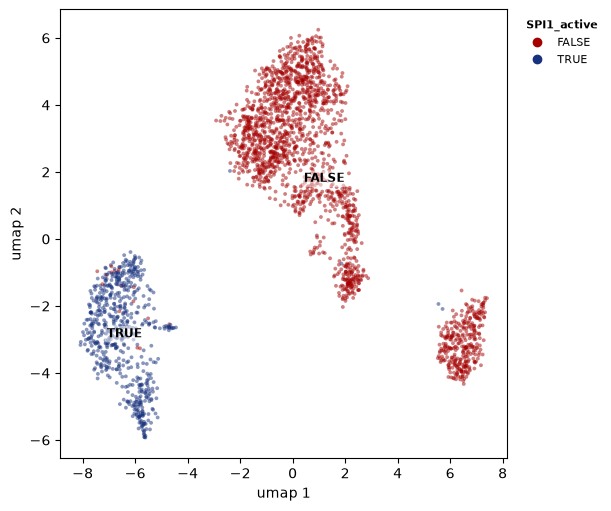

In [21]:
sc.add_obs(
    pl.DataFrame(
        {
            "cell_idx": auc_regulons.cell_indices.astype(np.uint32),
            "SPI1_active": binary_df["SPI1"],
        }
    )
)

bv.pl.embedding_plot(sc, "umap", "SPI1_active", label_by="SPI1_active")
plt.show()

Not ported to Python yet: the binary regulon heatmap
(`extract_binary_heatmap_data()` and `bixverse.plots::plot_binary_heatmap()`).

### ULM and MLM on the TF-to-gene links

AUCell only looks at whether the targets rank high in a cell. The TF-to-gene
table carries more than that: `tf_to_genes_correlations()` gave every link a
sign. `lm_activity()` uses it. It is the
[decoupler](https://academic.oup.com/bioinformaticsadvances/article/2/1/vbac016/6544613)
ULM/MLM: per cell, regress the normalised counts of all genes on the weights
of a TF's targets and take the t-value as the activity. Activated targets up
and repressed ones down gives a positive score. Normally you would use a
curated network like
[CollecTRI](https://academic.oup.com/nar/article/52/D1/D1029/7386439) here;
the inferred links do for the demo and keep the vignette offline.

In [22]:
lm_net = tf_gene_df.filter(pl.col("cor_sign") != 0).select(
    source=pl.col("tf_symbol"), target=pl.col("gene"), weight=pl.col("cor_sign")
)

lm_net.head()

source,target,weight
str,str,i32
"""CEBPB""","""ENSG00000188290""",1
"""SPI1""","""ENSG00000188290""",1
"""YBX1""","""ENSG00000188290""",1
"""CEBPB""","""ENSG00000187608""",1
"""CEBPD""","""ENSG00000187608""",1


In [23]:
ulm_scores = bv.pathways.lm_activity(
    sc, lm_net, lm_params=LmActivityParams(method="ulm")
)

ulm_scores.shape

(2490, 311)

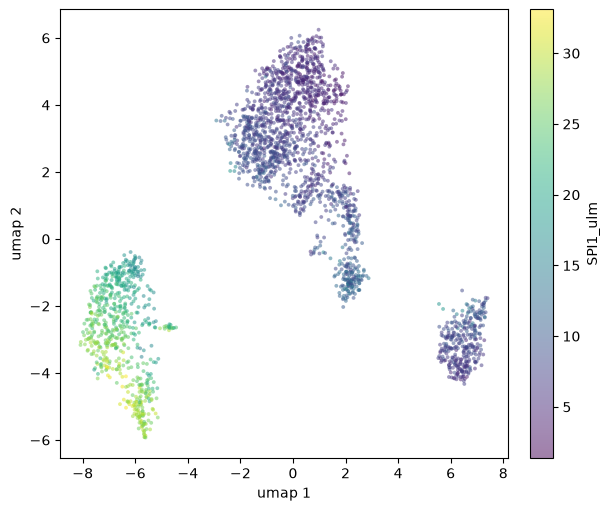

In [24]:
sc.add_obs(
    bv.pathways.get_data(ulm_scores, columns=["SPI1"]).rename({"SPI1": "SPI1_ulm"})
)

bv.pl.embedding_plot(sc, "umap", "SPI1_ulm", palette="viridis")
plt.show()

`method="mlm"` fits all TFs in one model, so TFs sharing many targets
compete for the signal instead of both lighting up. It errors on collinear
TFs, i.e., two regulons with identical or proportional target sets. Unlike
decoupler, genes that are zero in every cell stay in the model; on real data
that shifts the scores a little. `p_values=True` adds p-values and an FDR per
cell, but with thousands of correlated genes in each fit treat them as
descriptive.

In [25]:
mlm_scores = bv.pathways.lm_activity(
    sc, lm_net, lm_params=LmActivityParams(method="mlm")
)

spi1 = ulm_scores.columns.index("SPI1")
np.corrcoef(ulm_scores.values[:, spi1], mlm_scores.values[:, spi1])[0, 1]

np.float64(0.29048472751758914)

This is how you work with all types of "bag of genes" analyses for single
cell in `bixverse`.

## NMF on single cells

The methods so far have all started from either a pre-defined gene set, a
graph-based notion of locality, or a TF-centric regression framework. NMF
(non-negative matrix factorisation) takes yet another angle: it factorises
the expression matrix `V ≈ W H` into a small number of latent factors, where
`W` carries non-negative gene loadings and `H` carries non-negative cell
activations. The non-negativity constraint tends to push the factors into
something interpretable as additive gene programmes rather than abstract
directions of variance like PCA. `bixverse` implements
[HALS](https://proceedings.mlr.press/v39/kimura14.pdf) (Hierarchical
Alternating Least Squares) in Rust, which converges fast and scales nicely.

A few practical notes before diving in:

- NMF is non-convex: different random initialisations land in different
  local optima. The package therefore provides `nmf()` for a single run,
  `stabilised_nmf()` for multiple restarts, and `consensus_nmf()` which takes
  those restarts and returns the programmes they agree on. The last one is
  the right default for any serious analysis.
- Picking `k` is the eternal question. Too small and programmes get smushed
  together; too large and they fragment into redundant copies.
  `nmf_k_sweep()` turns that into something you can actually look at:
  stability against reconstruction error across a range of `k`. It is not a
  free lunch, but it beats licking your finger and seeing from where the wind
  comes... (Joke)
- NMF on a heterogeneous dataset often just rediscovers the obvious
  cell-type axis. The interesting use case is running it *within* a cell type
  to find finer-grained programmes (activation, exhaustion, cycling, etc.).
  We will do exactly that here.

We will focus on the T cells as an example. Think of your own use cases in
your data set and analyses.

### Identifying T cells

We will use the AUC scores from earlier to pull out the T cell population.
The Python package has no Otsu threshold yet, so we borrow the
binariser from the SCENIC section: a two-component Gaussian mixture on the
AUC with the threshold at the trough between the two modes, which is just as
data-driven for a bimodal distribution.

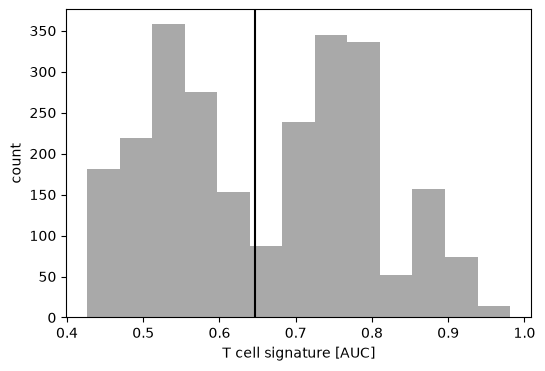

In [26]:
auc_thresholds = bv.pathways.binarise_regulon_activity(auc_scores).thresholds

t_cell_threshold = auc_thresholds.filter(pl.col("regulon") == "T cell")["threshold"][0]

auc_df = auc_scores.frame()

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(auc_df["T cell"], bins=13, color="darkgrey")
ax.axvline(t_cell_threshold, color="black")
ax.set_xlabel("T cell signature [AUC]")
ax.set_ylabel("count")
plt.show()

With the threshold in hand we grab the T cell IDs and recompute HVGs
*within* this subset. This matters: HVGs computed across all PBMCs are
dominated by inter-cell-type variation (T vs B vs monocyte). HVGs within T
cells expose the genes that actually vary across T cell states, which is what
we want NMF to factorise.

`get_hvg_data()` is a non-mutating variant of `find_hvg()`: it returns a
polars frame with the HVG metrics and an `is_hvg` flag, without overwriting
the HVGs stored on the object. Convenient when you want HVGs for a specific
downstream analysis without disturbing the global state.

In [27]:
t_cell_ids = auc_df.filter(pl.col("T cell") >= t_cell_threshold)["cell_id"].to_list()

hvg_t_cell_data = bv.pp.get_hvg_data(sc, cell_ids=t_cell_ids)

t_cell_hvg = hvg_t_cell_data.filter(pl.col("is_hvg"))["gene_id"].to_list()

print(f"{len(t_cell_ids)} T cells, {len(t_cell_hvg)} HVGs")

1259 T cells, 3000 HVGs


### Running a single NMF run

`nmf()` runs one NMF on the chosen cells and genes. The default
initialisation is NNDSVD, which is deterministic and gives a sensible
starting point.

In [28]:
t_cell_nmf_results = bv.nmf.nmf(sc, 10, cell_ids=t_cell_ids, gene_ids=t_cell_hvg)

t_cell_nmf_results

NmfResult (single-run HALS NMF)
  Source class:     SingleCells
  No genes:         3000
  No cells:         1259
  No components:    10
  Final loss:       6.353e+05
  Iterations:       50
  Converged:        True
  Preprocessing:    none

The result is an `NmfResult` carrying the `W` gene-loading matrix
(genes x components) and the `H` cell-activation matrix (components x
cells), plus the parameters and convergence info.

In [29]:
bv.nmf.get_w(t_cell_nmf_results)[:5, :6]

gene_id,comp_01,comp_02,comp_03,comp_04,comp_05
str,f64,f64,f64,f64,f64
"""ENSG00000188976""",1.710381,1.7041,9.9695e-11,1.091464,9.9989e-11
"""ENSG00000188290""",9.9844e-11,1.0022e-10,9.9695e-11,1.280667,9.9989e-11
"""ENSG00000187608""",9.9844e-11,0.466889,0.259936,5.192513,9.9989e-11
"""ENSG00000186827""",9.9844e-11,1.0022e-10,7.166567,1.0006e-10,9.9989e-11
"""ENSG00000242485""",4.80913,0.524939,2.891645,2.091083,1.082181


In [30]:
bv.nmf.get_h(t_cell_nmf_results)[:5, :5]

array([[2.86964085e-02, 2.72570793e-02, 2.69791838e-02, 2.52257809e-02,
        2.47780774e-02],
       [6.26783352e-03, 9.97814054e-11, 9.97814054e-11, 3.23927887e-02,
        2.77446080e-02],
       [1.49716279e-02, 4.53907736e-02, 4.34157662e-02, 1.29227778e-02,
        1.00306444e-10],
       [1.21529857e-02, 9.49110254e-04, 2.29259022e-02, 5.67319803e-04,
        9.99404795e-11],
       [3.52424234e-02, 1.82926338e-02, 2.68071126e-02, 4.03080247e-02,
        4.42688875e-02]])

### Running multiple NMF runs

For anything beyond exploratory work you want multiple restarts.
`stabilised_nmf()` runs `n_runs` HALS NMFs with random initialisations
(seeded by `seed + i`) and column-binds the resulting `W` matrices. Looking
at this stabilised data allows you to identify components that constantly
show up between random initialisations.

In [31]:
t_cell_nmf_results_stabilised = bv.nmf.stabilised_nmf(
    sc, 10, cell_ids=t_cell_ids, gene_ids=t_cell_hvg, n_runs=10
)

The W matrix here is wide: `n_genes x (k * n_runs)`. Each block of `k`
columns corresponds to one run. You can then use it for downstream consensus
analyses.

In [32]:
bv.nmf.get_w(t_cell_nmf_results_stabilised)[:5, :6]

gene_id,run_01.comp_01,run_01.comp_02,run_01.comp_03,run_01.comp_04,run_01.comp_05
str,f64,f64,f64,f64,f64
"""ENSG00000188976""",1.087447,0.041101,1.0004e-10,2.290183,9.9988e-11
"""ENSG00000188290""",9.9933e-11,1.0001e-10,1.0004e-10,1.0003e-10,9.9988e-11
"""ENSG00000187608""",9.9933e-11,1.0001e-10,1.0004e-10,1.0003e-10,9.9988e-11
"""ENSG00000186827""",9.9933e-11,1.0001e-10,7.210502,1.0003e-10,9.9988e-11
"""ENSG00000242485""",1.701236,0.208525,3.782568,2.314945,1.342366


The H matrices are kept per run, since each random initialisation gives a
different cell-activation pattern (components are not aligned across runs
without further work).

In [33]:
[h.shape for h in bv.nmf.get_h(t_cell_nmf_results_stabilised)]

[(10, 1259),
 (10, 1259),
 (10, 1259),
 (10, 1259),
 (10, 1259),
 (10, 1259),
 (10, 1259),
 (10, 1259),
 (10, 1259),
 (10, 1259)]

The run with the lowest final reconstruction loss is the most natural
starting point for a single-run analysis. `get_best_run()` returns it as an
`NmfResult`, identical in shape to the output of `nmf()`.

In [34]:
best_run = bv.nmf.get_best_run(t_cell_nmf_results_stabilised)

best_run

NmfResult (single-run HALS NMF)
  Source class:     SingleCells
  No genes:         3000
  No cells:         1259
  No components:    10
  Final loss:       6.356e+05
  Iterations:       NA
  Converged:        True
  Preprocessing:    none

### Consensus NMF

Picking the lowest-loss restart is a reasonable default, but it dodges the
question you actually care about: did the restarts agree? Consensus NMF
(cNMF, [Kotliar, et al.](https://elifesciences.org/articles/43803)) answers
it directly. Pool the components of every restart, drop the ones sitting on
their own in the pool, k-means the survivors into `k` groups, and take the
median of each group. What comes out is the programme structure the
restarts agree on, and the mean silhouette of those clusters says how
strongly they agreed.

Before fitting, though, you need a `k`. `nmf_k_sweep()` runs the consensus
step across a range of ranks and reports stability against reconstruction
error, keeping no factors, so a wide sweep stays affordable.

In [35]:
t_cell_k_sweep = bv.nmf.nmf_k_sweep(
    sc,
    range(2, 13),
    cell_ids=t_cell_ids,
    gene_ids=t_cell_hvg,
    n_runs=10,
    nmf_consensus_params=NmfConsensusParams(density_threshold=2.0),
)

t_cell_k_sweep

NmfKSweepResult (consensus NMF k sweep)
  Source class:     SingleCells
  k range:          2 to 12
  No runs per k:    10
  Most stable k:    2 (stability = 0.9987)

shape: (11, 8)
┌─────┬───────────┬────────────┬─────────────┬─────────────┬───────────┬─────────────┬─────────────┐
│ k   ┆ stability ┆ best_error ┆ median_erro ┆ consensus_f ┆ n_dropped ┆ n_empty_clu ┆ n_converged │
│ --- ┆ ---       ┆ ---        ┆ r           ┆ ailed       ┆ ---       ┆ sters       ┆ ---         │
│ i64 ┆ f64       ┆ f64        ┆ ---         ┆ ---         ┆ i64       ┆ ---         ┆ i64         │
│     ┆           ┆            ┆ f64         ┆ bool        ┆           ┆ i64         ┆             │
╞═════╪═══════════╪════════════╪═════════════╪═════════════╪═══════════╪═════════════╪═════════════╡
│ 2   ┆ 0.998748  ┆ 0.350482   ┆ 0.350498    ┆ false       ┆ 0         ┆ 0           ┆ 10          │
│ 3   ┆ 0.879014  ┆ 0.346046   ┆ 0.346063    ┆ false       ┆ 0         ┆ 0           ┆ 10          │
│ 4   ┆ 0.

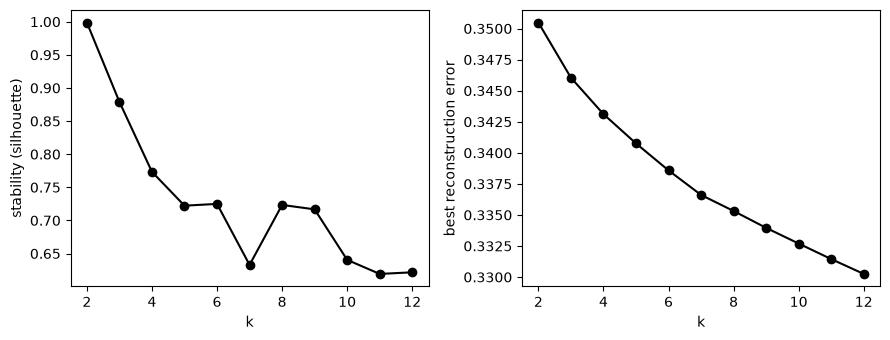

In [36]:
sweep = t_cell_k_sweep.frame

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True)
axes[0].plot(sweep["k"], sweep["stability"], marker="o", color="black")
axes[0].set_ylabel("stability (silhouette)")
axes[1].plot(sweep["k"], sweep["best_error"], marker="o", color="black")
axes[1].set_ylabel("best reconstruction error")
for ax in axes:
    ax.set_xlabel("k")
fig.tight_layout()
plt.show()

Error falls monotonically with `k`, so it would happily push you to the
largest rank you can afford. Stability is the counterweight: take the last
`k` before it falls away, while the error curve is still coming down. Here
stability plateaus from 5 to 9 (with a dip at 7) and drops at 10, so that is
9, not the 10 we picked by eye for the runs above. Worth knowing before
writing up ten programmes when the data supports nine. (Identifying two
components is always trivial and unlikely to be the true signal.)

`density_threshold=2` turns the outlier filter off, since cosine distance
cannot exceed 2. Left on, components whose neighbours sit too far away get
dropped, and if fewer than `k` survive the fit errors instead of returning
something degenerate. Sensible on real data with enough restarts; with 8 it
fires more often than it should. `get_stability()` gives you the
`local_density` values to pick a real threshold from.

In [37]:
t_cell_nmf_consensus = bv.nmf.consensus_nmf(
    sc,
    9,
    cell_ids=t_cell_ids,
    gene_ids=t_cell_hvg,
    n_runs=10,
    nmf_consensus_params=NmfConsensusParams(density_threshold=2.0),
)

t_cell_nmf_consensus

ConsensusNmfResult (consensus HALS NMF)
  Source class:     SingleCells
  No genes:         3000
  No cells:         1259
  No components:    9
  No runs:          10
  Stability:        0.6836
  Relative error:   0.3354
  Dropped:          0 / 90 components
  Preprocessing:    none

`W` and `H` come back in exactly the shape `nmf()` gives you, so everything
downstream is unchanged. What is new is `get_stability()`.

In [38]:
consensus_diag = bv.nmf.get_stability(t_cell_nmf_consensus)

print(f"stability: {consensus_diag['stability']:.3f}")
consensus_diag["cluster_sizes"]

stability: 0.684


cluster,n
i64,i64
0,20
1,7
2,10
3,7
4,10
5,10
6,5
7,10
8,11


The per-component table records where each restart's components landed.
`component_id` uses the same `run_XX.comp_YY` naming as the `w_all` columns
of a stabilised fit, so at matching `k` and `n_runs` the two line up directly
and you can go back to the raw restarts behind any cluster.

In [39]:
consensus_diag["clusters"].head()

component_id,run,component,pooled_idx,cluster,local_density,silhouette,kept
str,i64,i64,i64,i64,f64,f64,bool
"""run_01.comp_01""",0,0,0,0,0.003255,0.916863,true
"""run_01.comp_02""",0,1,1,0,0.032111,0.844915,true
"""run_01.comp_03""",0,2,2,2,0.034343,0.857009,true
"""run_01.comp_04""",0,3,3,6,0.092704,0.597719,true
"""run_01.comp_05""",0,4,4,1,0.091019,0.363154,true


With 10 restarts, a cluster holding 10 components is a programme every run
found. A thin one is a programme only some initialisations saw, and that is
worth knowing before you write it up.

Memory, not runtime, is what bites here. The restarts are dense and all live
at once, so budget roughly `n_cells * k * n_runs` floats on top of the
counts. At a few hundred thousand cells with `n_runs=50` that adds up fast,
and the honest answer is to run consensus NMF on `MetaCells` instead. See
the meta cell vignette.

### Downstream analysis

What you do next depends entirely on what you are after. Some natural
directions:

- **Inspect the components**: rank genes by loading in `W` to read off what
  each component represents. Components that recover known programmes
  (cytotoxicity, exhaustion, ribosomal, IFN response, etc.) are a good sign;
  components that load on uninteresting genes you can ignore or merge.
- **Score cells**: `H` gives you per-cell activations for each programme.
  Project them onto your UMAP, correlate against existing annotations, or
  use them as features for downstream clustering.
- **Add activations to the obs table**: `bv.nmf.get_data()` on an
  `NmfResult` or a `ConsensusNmfResult` returns a polars frame of cell
  activations keyed on `cell_idx` that goes straight into `add_obs()`, the
  same way module scores did earlier.

We leave the choice of analysis here to you: the right downstream depends on
the biology and your questions to the data, not the API.

## Clean up

In [40]:
tempdir_pbmc.cleanup()